[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/porterjenkins/byu-cs474/blob/master/lab9_transfer_learning.ipynb)

# Transfer Learning/Fine-Tuning




During training, neural networks often learn features that are useful for a wide variety of tasks. For example, the earliest layers of convolution networks often learn very basic visual features, such as edge detection. These task-agnostic features can be very useful when applied to other tasks. Transfer learning or fine-tuning is a technique that takes a network pretrained on one task and trains it on another. The idea is to tweak or tune the parameters on the new task, rather than making huge changes in learning. Fine-tuning is often quicker than learning on the new task from scratch, and can even lead to better overall performance and generalization.

Unfreezing a pretrained network is a fine-tuning technique that can be helpful when training a network on a difficult task with limited data.
If we allow the network to train its earliest layers immediately, then the earliest layers will forget all of the useful task-agnostic features they learned previously. So, rather than training all of the model weights at once, we learn on the last few layers (which are the most task-specific in the network). We can also gradually start training on the earlier layers as training progresses.

In this lab, you will compare unfreezing fine-tuning techniques against training a model from scratch. You will use the large ResNet-152 model to learn the small Bird Species Classification dataset.



---

## Grading



- 20% Analyze Dataset
- 20% Implementing `BirdNet`
- 20% Implementing `train()`
- 30% Running finetuning experiment
- 10% Answering questions

---

## Lab Setup

In [89]:
import zipfile
import os
import sys
from PIL import Image, ImageOps
import numpy as np
from matplotlib import pyplot as plt
import time
from dataclasses import dataclass

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
import torchvision.models as models
from torchvision import datasets, transforms

In [90]:
device = torch.device("cuda")

---

## Analyze `BirdDataset`



Start by first downloading the dataset from Kaggle.

#### Help for downloading kaggle datasets
Downloading Kaggle datasets requires authentication, so you can't just download from a url. Here are some step-by-step instructions of how to get Kaggle datasets in Colab.

1. Create an API key in Kaggle
    - Click on profile photo
    - Go to 'My Account'
    - Scroll down to the API access section and click "Create New API Token"
    - `kaggle.json` is now downloaded to your computer

2. Upload the API key and install the Kaggle API client by running the next cell (run it again if it throws an error the first time). Also, `files.upload()` may not work in Firefox. One solution is to expand the Files banner (indicated by the '>' tab on the left side of the page) and use that to upload the key.

In [91]:
# Run this cell and select the kaggle.json file downloaded
# from the Kaggle account settings page.
from google.colab import files
files.upload()
# Next, install the Kaggle API client.
!pip install -q kaggle
# Let's make sure the kaggle.json file is present.
!ls -lha kaggle.json
# The Kaggle API client expects this file to be in ~/.kaggle,
# so move it there.
!mkdir -p ~/.kaggle
!mv kaggle.json ~/.kaggle/
# This permissions change avoids a warning on Kaggle tool startup.
!chmod 600 ~/.kaggle/kaggle.json

Saving kaggle.json to kaggle.json
-rw-r--r-- 1 root root 68 Nov 10 22:17 kaggle.json


3. Copy the desired dataset locally

In [92]:
# Example download command for dataset found here: https://www.kaggle.com/akash2907/bird-species-classification
!kaggle datasets download -d akash2907/bird-species-classification

Dataset URL: https://www.kaggle.com/datasets/akash2907/bird-species-classification
License(s): CC-BY-NC-SA-4.0
bird-species-classification.zip: Skipping, found more recently modified local copy (use --force to force download)


The `BirdDataset` is implemented for you below. Instantiate a `train_dataset` and `val_dataset`.

In [93]:
class BirdDataset(Dataset):
    def __init__(self, zip_file='bird-species-classification.zip', size=256, train=True, upload=False):
        super(BirdDataset, self).__init__()

        self.train = train
        extract_dir = os.path.splitext(zip_file)[0]
        if not os.path.exists(extract_dir):
            os.makedirs(extract_dir)
            self.extract_zip(zip_file, extract_dir)
            # We resize the images - originally they are high resolution. We could do this
            # in the DataLoader, but it will read the full-resolution files from disk
            # every time before resizing them, making training slow
            self.resize(extract_dir, size=size)

        postfix = 'train' if train else 'test'

        if train:
            # The bird-species dataset mistakenly has a train_data folder inside of train_data
            self.dataset_folder = datasets.ImageFolder(os.path.join(extract_dir, 'train_data', 'train_data'), transform=transforms.Compose([transforms.ToTensor()]))
        else:
            self.dataset_folder = datasets.ImageFolder(os.path.join(extract_dir, 'test_data', 'test_data'), transform=transforms.Compose([transforms.ToTensor()]))

    def extract_zip(self, zip_file, extract_dir):
        print("Extracting", zip_file)
        with zipfile.ZipFile(zip_file, 'r') as zip_ref:
            zip_ref.extractall(extract_dir)

    def resize(self, path, size=256):
        """Resizes all images in place"""
        print("Resizing images")
        dirs = os.walk(path)
        for root, dirs, files in os.walk(path):
            for item in files:
                name = os.path.join(root, item)
                if os.path.isfile(name):
                    im = Image.open(name)
                    im = ImageOps.fit(im, (size, size))
                    im.save(name[:-3] + 'bmp', 'BMP')
                    os.remove(name)
                else:
                    print(f"else {name}")

    def __getitem__(self, i):
        return self.dataset_folder[i]

    def __len__(self):
        return len(self.dataset_folder)

In [94]:
train_dataset = BirdDataset(train=True)
val_dataset = BirdDataset(train=False)

Print out the number of instances of each class in the `train_dataset` and `val_dataset`.

In [95]:
for name, ds in [('train', train_dataset), ('val', val_dataset)]:
    classes = ds.dataset_folder.classes
    counts = np.bincount(ds.dataset_folder.targets, minlength=len(classes))
    print(f"Number of {name} instances: {len(ds)}")
    for i in range(len(classes)):
        print(f"{name} {classes[i]}: {counts[i]}")

Number of train instances: 150
train blasti: 15
train bonegl: 6
train brhkyt: 5
train cbrtsh: 7
train cmnmyn: 7
train gretit: 6
train hilpig: 10
train himbul: 18
train himgri: 20
train hsparo: 9
train indvul: 9
train jglowl: 6
train lbicrw: 6
train mgprob: 6
train rebimg: 10
train wcrsrt: 10
Number of val instances: 157
val blasti: 15
val bonegl: 7
val brhkyt: 6
val cbrtsh: 7
val cmnmyn: 8
val gretit: 7
val hilpig: 10
val himbul: 19
val himgri: 20
val hsparo: 9
val indvul: 9
val jglowl: 6
val lbicrw: 6
val mgprob: 7
val rebimg: 11
val wcrsrt: 10


Print out a single image for each class in a 4x4 display.

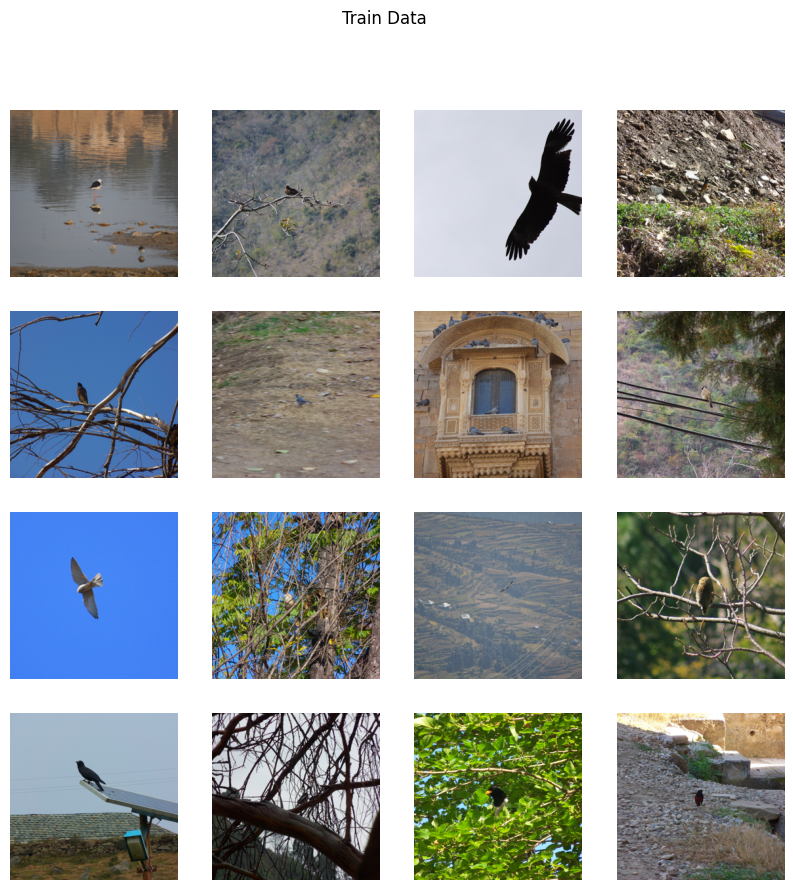

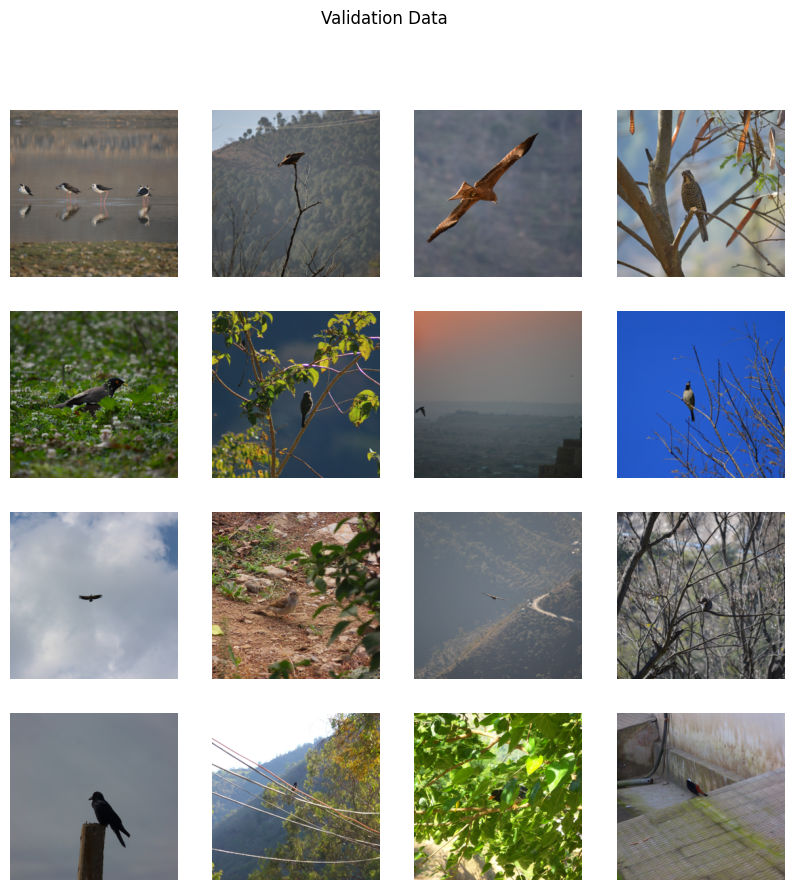

In [96]:


plt.figure(figsize=(10, 10))
plt.suptitle("Train Data")
seen = []
for img, label in train_dataset:
    if label not in seen:
        ax = plt.subplot(4, 4, len(seen)+1)
        plt.imshow(img.permute(1, 2, 0))
        seen.append(label)
        ax.axis('off')
    if len(seen) == 16:
        break
plt.show()

plt.figure(figsize=(10, 10))
plt.suptitle("Validation Data")
seen = []
for img, label in val_dataset:
    if label not in seen:
        ax = plt.subplot(4, 4, len(seen)+1)
        plt.imshow(img.permute(1, 2, 0))
        seen.append(label)
        ax.axis('off')
    if len(seen) == 16:
        break
plt.show()

You will notice that not only do we have a small training dataset (150 images), some of the images are potentially difficult to classify because of how small the bird appears in the image. If you investigated the images further you would notice that many images of a given class are subsequent snapshots of the same bird. This will make generalization hard and overfitting easy, especially with a large network.

---

## Implement `BirdNet`





Implement the `BirdNet`: a wrapper class adding functionality to a (pretrained) `ResNet`.


### Implement `__init__()`

- The `BirdNet` should first instantiate a `models.resnet152` object and optionally, load in pretrained weights (look at https://pytorch.org/vision/stable/models.html for more information about using pretrained weights). We suggest using `models.ResNet152_Weights.IMAGENET1K_V1`.
- Overwrite the final layer in the ResNet to linearly map (with `nn.Linear`) the previous layers features to `n_classes`.
- Freeze all weights except the final layer. You can do this with calling `.requires_grad = False` on the parameters or calling `.requires_grad(False)` on the layers.

In [97]:
# Implemented in lower cell


### Implement `unfreeze()`


Implement `unfreeze()` to unfreeze the last `n_layers` of your model. Do not treat the sequential or bottleneck layers in the ResNet as a single layer; we consider a convolutional layer or linear layer as a single layer. You may optionally treat a batchnorm layer as its own layer or as part of a conv/linear layer. ReLU layers do not have parameters, so they can't be frozen/unfrozen.

**Tip**: *You can print out a `models.resnet152` object to get an idea of how many input features are used in the last layer as well as the structure and naming convention used by the ResNet to know how to unfreeze `n_layers`.*

In [98]:
# Implemented in lower cell

Create a temporary resnet152 model and print it here to see the structure of the network and the naming conventions. You can iterate over `.named_parameters()` to get the name and parameter object, respectively, to verify the naming scheme. This function can make your unfreezing function simpler.

In [99]:
resnet = models.resnet152()
for param in resnet.named_parameters():
    print(param[0])

conv1.weight
bn1.weight
bn1.bias
layer1.0.conv1.weight
layer1.0.bn1.weight
layer1.0.bn1.bias
layer1.0.conv2.weight
layer1.0.bn2.weight
layer1.0.bn2.bias
layer1.0.conv3.weight
layer1.0.bn3.weight
layer1.0.bn3.bias
layer1.0.downsample.0.weight
layer1.0.downsample.1.weight
layer1.0.downsample.1.bias
layer1.1.conv1.weight
layer1.1.bn1.weight
layer1.1.bn1.bias
layer1.1.conv2.weight
layer1.1.bn2.weight
layer1.1.bn2.bias
layer1.1.conv3.weight
layer1.1.bn3.weight
layer1.1.bn3.bias
layer1.2.conv1.weight
layer1.2.bn1.weight
layer1.2.bn1.bias
layer1.2.conv2.weight
layer1.2.bn2.weight
layer1.2.bn2.bias
layer1.2.conv3.weight
layer1.2.bn3.weight
layer1.2.bn3.bias
layer2.0.conv1.weight
layer2.0.bn1.weight
layer2.0.bn1.bias
layer2.0.conv2.weight
layer2.0.bn2.weight
layer2.0.bn2.bias
layer2.0.conv3.weight
layer2.0.bn3.weight
layer2.0.bn3.bias
layer2.0.downsample.0.weight
layer2.0.downsample.1.weight
layer2.0.downsample.1.bias
layer2.1.conv1.weight
layer2.1.bn1.weight
layer2.1.bn1.bias
layer2.1.conv2.we

In [100]:
class BirdNet(nn.Module):
    def __init__(self, n_classes, pretrained_weights):
        super().__init__()
        # Only freeze the model weights if you are using pretrained weights
        self.net = models.resnet152(weights=pretrained_weights)
        self.net.fc = nn.Linear(self.net.fc.in_features, n_classes)
        if pretrained_weights is not None:
          self.freeze()

    def layer_groups(self):
        groups = []
        for m in self.net.modules():
            if isinstance(m, (nn.Linear, nn.Conv2d)):
                groups.append([m])
            elif isinstance(m, nn.BatchNorm2d):
                groups[-1].append(m)
        return groups

    def freeze(self):
        self.unfreeze(1)

    def unfreeze(self, n_layers):
        for param in self.net.parameters():
            param.requires_grad = False
        for group in self.layer_groups()[-n_layers:]:
            for m in group:
              for p in m.parameters():
                p.requires_grad = True

    def forward(self, x):
        return self.net(x)

---

## Training

In [101]:
@torch.no_grad()
def accuracy(y_hat, y_truth):
    preds = torch.argmax(y_hat, dim=1)
    acc = torch.mean((preds == y_truth).float())
    return acc.item()


@torch.no_grad()
def evaluate(model, loss_fn, val_loader):
    val_losses = 0
    val_accs = 0
    # model.eval() so that batchnorm and dropout work in eval mode
    model.eval()

    for x, y_truth in val_loader:
        x, y_truth = x.to(device), y_truth.to(device)
        y_hat = model(x)
        val_losses += loss_fn(y_hat, y_truth).item() * len(x)
        val_accs += accuracy(y_hat, y_truth) * len(x)

    model.train()
    return val_losses/len(val_dataset), val_accs/len(val_dataset)


Implement the `train()` function. Keep track of the usual performance metrics (training/validation losses and accuracies) and additionally keep track of how long, in seconds, training took (this is referred to as wallclock training time).

There are two additional arguments in `train()`: `slowly_unfreeze` and `unfreeze_interval`.
 If `slowly_unfreeze=True` then for every `unfreeze_interval` number of steps you should unfreeze an additional layer from your model.

In [112]:
def train(model, optimizer, n_optimization_steps, log_interval, slowly_unfreeze, unfreeze_interval, accum_steps=4):
    train_losses = []
    train_accs = []
    val_losses = []
    val_accs = []

    train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=64)
    loss_fn = nn.CrossEntropyLoss()
    data_iter = iter(train_loader)

    n_unfrozen = 1
    model.train()

    start_time = time.time()

    for step in range(n_optimization_steps):
      if slowly_unfreeze and step > 0 and step % unfreeze_interval == 0:
                n_unfrozen += 1
                model.unfreeze(n_layers=n_unfrozen)

      try:
          x, y_truth = next(data_iter)
      except StopIteration:
          data_iter = iter(train_loader)
          x, y_truth = next(data_iter)

      x, y_truth = x.to(device), y_truth.to(device)
      optimizer.zero_grad()
      step_loss, step_acc = 0.0, 0.0
      for xc, yc in zip(x.chunk(accum_steps), y_truth.chunk(accum_steps)):
        y_hat = model(xc)
        loss = loss_fn(y_hat, yc) * len(xc) / len(x)
        loss.backward()
        step_loss += loss.item()
        step_acc += accuracy(y_hat, yc) * len(xc) / len(x)
      optimizer.step()
      train_losses.append(step_loss)
      train_accs.append(step_acc)
      if step % log_interval == 0:
          val_loss, val_acc = evaluate(model, loss_fn, val_loader)
          val_losses.append(val_loss)
          val_accs.append(val_acc)


    end_time = time.time()
    return train_losses, train_accs, val_losses, val_accs, end_time - start_time

To compare how well finetuning works you will perform a set of experiments. There are four models you will train for `n_trials >= 3`:
- `res-reinit`: A reinitialized (not pretrained) resnet model. This is the baseline.
- `res1`: A pretrained resnet model with only the last layer unfrozen.
- `res3`: A pretrained resnet model with the last 3 layers unfrozen.
- `res10-slow`: A pretrained resnet model with the last 10 layers **slowly** unfrozen.

For each model average the results across the `n_trials` and plot the val accuracy across time for each model and print out the average wallclock time and time per optimization step (i.e. wallclock_time / optimization_step) . **Do not forget to recreate the model and optimizer between each trial.**


**Tip:** Make sure everything is implemented correctly before running all `n_trials` on all four models. We found that a learning rate of .001 worked well for 100 optimization steps.

In [111]:
def train_trials(n_trials, model_kwargs, n_unfreeze=None, slowly_unfreeze=False):
    all_train_losses = []
    all_train_accs = []
    all_val_losses = []
    all_val_accs = []
    all_wallclock_times = []
    for n in range(n_trials):
        # TODO: instantiate a model using model_kwargs
        model = BirdNet(**model_kwargs).to(device)
        if n_unfreeze is not None:
          model.unfreeze(n_unfreeze)

        optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

        # train the model
        train_losses, train_accs, val_losses, val_accs, wallclock_time = train(model, optimizer, n_optimization_steps=100, log_interval=10, slowly_unfreeze=slowly_unfreeze, unfreeze_interval=10)
        # TODO: Store train & val loss, accuracies, and total wallclock time
        all_train_losses.append(train_losses)
        all_train_accs.append(train_accs)
        all_val_losses.append(val_losses)
        all_val_accs.append(val_accs)
        all_wallclock_times.append(wallclock_time)
        del model, optimizer
        torch.cuda.empty_cache()
        print(f"Trial {n} done")

    return all_train_losses, all_train_accs, all_val_losses, all_val_accs, all_wallclock_times

0.02 GB still allocated
Running res-reinit...
Trial 0 done
Trial 1 done
Trial 2 done
Running res1...
Trial 0 done
Trial 1 done
Trial 2 done
Running res3...
Trial 0 done
Trial 1 done
Trial 2 done
Running res10-slow...
Trial 0 done
Trial 1 done
Trial 2 done
res-reinit: 190.6s total, 1.906s per step
res1: 187.0s total, 1.870s per step
res3: 186.1s total, 1.861s per step
res10-slow: 185.2s total, 1.852s per step


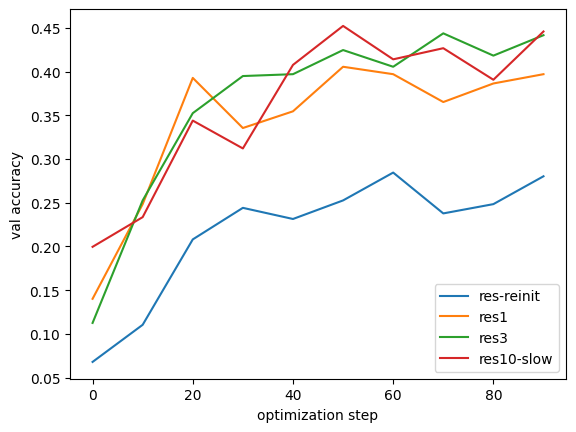

In [114]:
# Run trials for all models
import gc, sys

sys.last_traceback = None
gc.collect()
torch.cuda.empty_cache()
print(f"{torch.cuda.memory_allocated()/1e9:.2f} GB still allocated")

n_trials = 3
pre = {'n_classes': 100, 'pretrained_weights': models.ResNet152_Weights.IMAGENET1K_V1}

# Run sequentially and clear memory in between to avoid OOM
results = {}

print("Running res-reinit...")
results['res-reinit'] = train_trials(n_trials=n_trials, model_kwargs={'n_classes': 100, 'pretrained_weights': None})
gc.collect()
torch.cuda.empty_cache()

print("Running res1...")
results['res1'] = train_trials(n_trials=n_trials, model_kwargs=pre, n_unfreeze=1)
gc.collect()
torch.cuda.empty_cache()

print("Running res3...")
results['res3'] = train_trials(n_trials=n_trials, model_kwargs=pre, n_unfreeze=3)
gc.collect()
torch.cuda.empty_cache()

print("Running res10-slow...")
results['res10-slow'] = train_trials(n_trials=n_trials, model_kwargs=pre, slowly_unfreeze=True)
gc.collect()
torch.cuda.empty_cache()

for name, (_, _, _, val_acc, wall_time) in results.items():
  plt.plot(range(0, 100, 10), np.mean(val_acc, axis=0), label=name)
  print(f"{name}: {np.mean(wall_time):.1f}s total, {np.mean(wall_time)/100:.3f}s per step")
plt.xlabel("optimization step")
plt.ylabel("val accuracy")
plt.legend()
plt.show()

---

## Questions



- Which model performed the best?
- How do the finetuned models compare to the reinitialized model in terms of time?
- Why are the ImageNet weights helpful to learning the Bird dataset?
- Why do we only unfreeze the last few layers?
- What are some pros and cons of pretraining?

It seems like res1 and res10-slow performed similarly, both being near the best. The finetuned models all had higher validation accuracy than the reinitialized model, even though all of the models were fairly comparable in time.

The finetuned models were faster, but only by a few centiseconds. Over a long enough period this would be significant, but in this case it is less relevant.

The ImageNet weights were useful because they are in a better starting place than random weights for this problem. The Bird dataset is composed of images, so these weights are especially useful.

We only unfreeze the last few layers because that allows the later layers to have more of an impact on the output. Before, the weights and biases of the last layers would have a very small impact on the overall output, so this helps the gradients of the last layers be more substantial. We assume the preinitalized weights are mostly correct already, and only need small adjustments to be fully correct.

Pros of pretraining include potentially requiring less training time to get to a desired accuracy. Cons are that if we do not pretrain correctly, that may mean we are stuck in an undesirable valley, leading to longer training times or a complete failure to converge on an acceptable solution.